## Faltung
$f\ast g (x,y) = \sum_{\alpha=-\infty}^\infty \sum_{\beta=-\infty}^\infty f(\alpha, \beta) g(x-\alpha, y-\beta)$

Wird der Kernel nicht um 180° gedreht, spricht man von **Kreuzkorrelation**. `cv2.filter2D()` berechnet eine Kreuzkorrelation – bei symmetrischen Kerneln (Mittelwert, Gauß, Laplace) ist das egal.

Bild: [Robert Johnson](https://en.wikipedia.org/wiki/Robert_Johnson) (Bluesmusiker, der der Legende nach seine Seele an den Teufel verkauft hat, um gut Gitarre zu spielen.)

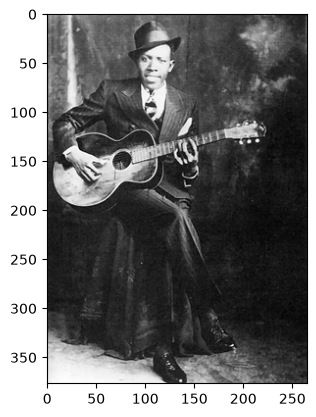

In [1]:
import numpy as np
import cv2 
import matplotlib.pyplot as plt

img = cv2.imread('Robert_Johnson.png',0)
img_gauss = cv2.imread('Robert_Johnson_gauss.png',0)
img_snp = cv2.imread('Robert_Johnson_snp.png',0)

plt.imshow(img,cmap='gray')
L= 256

Definieren Sie hier verschiedene Kernel für die in der Vorlesung besprochenen Anwendungen:

In [2]:
k_identity = np.array([[0, 0, 0],
                       [0, 1, 0],
                       [0, 0, 0]])

# Hier Kernel ergänzen
k_mean = np.array([[1, 1, 1],
                   [1, 1, 1],
                   [1, 1, 1]]) / 9
k_gauß = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]]) / 16



Wie lautet die fehlende Zeile Code um Faltung für einen einzelnen Pixel auszurechnen?

Für eine echte Faltung wird der Kernel vorher um 180° gedreht (`np.flip()`).

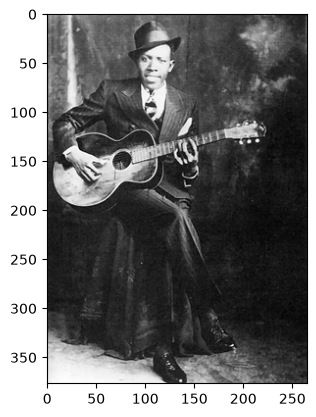

In [3]:
def conv2d(img, kernel, pad):
    """
    Inputs:
    img: Input Bild
    kernel: Faltungsfilter
    pad: Anzahl der hinzugefügten Randpixel

    Output:
    img_conv: gefaltetes Bild
    """
    kernel = np.flip(kernel)  # Faltung: Kernel um 180° drehen
    m, n = kernel.shape
    y, x = img.shape
    img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0) #Zero Padding
    
    img_conv = np.zeros((y, x))
    for i in range(y):
        for j in range(x):
            img_conv[i][j] = np.sum(img[i:i+m, j:j+n] * kernel)
    return img_conv

img_conv = conv2d(img, k_identity, 1)
plt.imshow(img_conv,cmap='gray')

In [4]:
# Zahlenbeispiel aus der Vorlesung: Pixel in Zeile 1, Spalte 3 muss 145 ergeben
I = np.array([[3, 3, 3, 0, 1], [2, 9, 8, 0, 6], [2, 6, 8, 5, 5], [6, 6, 4, 8, 0], [5, 10, 6, 10, 3]], np.uint8)
K = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print(conv2d(I, K, 1)[1, 3])

145.0


Wenden Sie die Kernel auf das Ursprungsbild und dessen Variationen mit Rauschen, d.h. `img_gauss` und `img_snp`, an. (Für die Variationen den Code unten ausführen!)

Machen Sie die Kanten sichtbar. (Eventuell ist vorher Glättung notwendig.)

Wie sieht das Bild aus, wenn ein Kernel zur Schärfung angewendet wird, um die Unschärfe der Glättung zu entfernen?

*Hinweis:* Kantenfilter liefern negative Werte. Verwenden Sie in `cv2.filter2D()` deshalb `cv2.CV_64F` statt `-1` (sonst werden negative Werte auf 0 abgeschnitten) und zeigen Sie den Betrag mit `np.abs()` an.

Sobel: $G_x = I \ast F_x$, $G_y = I \ast F_y$, Kantenstärke $G = \sqrt{G_x^2 + G_y^2}$ (oft auch $|\nabla I|$ geschrieben, $\nabla$ = Nabla-Operator)

Tipp: [`cv2.filter2D()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga27c049795ce870216ddfb366086b5a04) ist effizienter im Rechnen als `conv2d()`

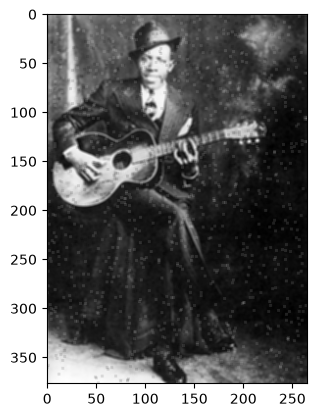

In [5]:
img_conv = cv2.filter2D(img_snp, np.abs(cv2.CV_64F), k_mean)
plt.imshow(img_conv,cmap='gray')

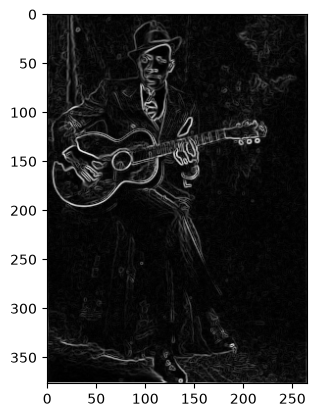

In [6]:
Fx = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])
Fy = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

gx = conv2d(img, Fx, 1)
gy = conv2d(img, Fy, 1)
G = np.sqrt(gx**2 + gy**2)
plt.imshow(G,cmap='gray')

### Gausssches Rauschen

Gaußsche Normalverteilung der Fehlerwerte

True

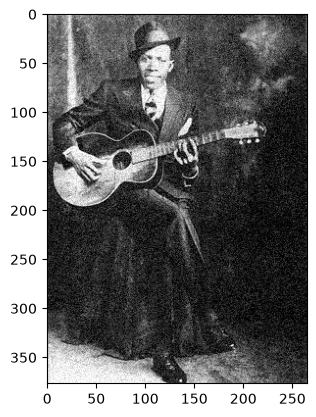

In [7]:
def add_gauss(img, sigma):
    """
    Input:
    img: Bild
    sigma: Standardabweichung
    Output:
    img: Bild mit Gausschem Rauschen
    """
    gauss = np.random.normal(0,sigma,img.size)
    gauss = gauss.reshape(img.shape[0],img.shape[1])
    img = img+gauss
    img[np.where(img > L-1)] = L - 1
    img[np.where(img < 0)] = 0
    return img

img_gauss = add_gauss(img, 20)
plt.imshow(img_gauss, cmap="gray")
cv2.imwrite("Robert_Johnson_gauss.png", img_gauss)

### Salz und Pfeffer Rauschen

Gesättigte Farbwerte der Pixel

True

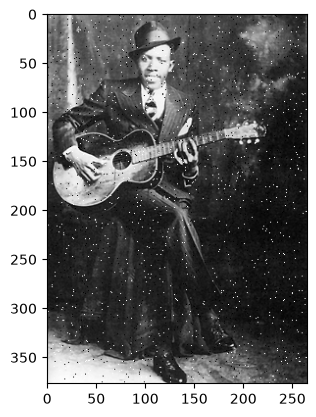

In [8]:
import random
def add_snp(img, px):
    """
    Input:
    img: Bild
    px: Zahl der Pixel mit Rauschen
    Output:
    img: Bild mit Salz und Pfeffer Rauschen
    """
    img = img.copy()  # Original nicht verändern
    m, n = img.shape

    for i in range(px):
        y_coord=random.randint(0, m - 1)
        x_coord=random.randint(0, n - 1)
        img[y_coord][x_coord] = 255

    for i in range(px):
        y_coord=random.randint(0, m - 1)
        x_coord=random.randint(0, n - 1)
        img[y_coord][x_coord] = 0
    return img


img_snp = add_snp(img,1000)
plt.imshow(img_snp, cmap="gray")
cv2.imwrite('Robert_Johnson_snp.png', img_snp)

Entfernen Sie das Salz und Pfeffer Rauschen mit einem Median Filter.

Wieso funktioniert hier der Mittelwert-Filter nicht so gut?

Tipp: [`cv2.medianBlur()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga564869aa33e58769b4469101aac458f9)

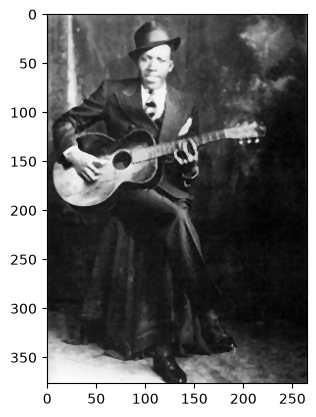

In [9]:
img_snp = cv2.imread('Robert_Johnson_snp.png',0)
img_restored = cv2.medianBlur(img_snp, 3)
plt.imshow(img_restored, cmap="gray")

## Morphologie

Hier werden die Bilder importiert. 
Um diese sinnvoll weiterzuverarbeiten, wird sichergestellt, dass sie binär sind, d.h. alle Werte werden auf 0 bzw. 1 gesetzt.

Bilder: 
- Binärmaske von Zahnrädern
- Binärmaske von Erythrozyten
- Binärmaske von Fingerabdruck
- Binärmaske von Nachthimmel

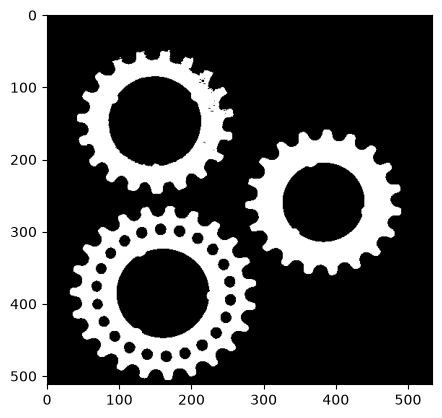

In [10]:
import numpy as np
import cv2 
import matplotlib.pyplot as plt

L = 256
def binary(img):
    img[np.where(img<=L/2)] = 0
    img[np.where(img>L/2)] = 1
    return img
gears = binary(cv2.imread('gears.png',0))
cells = binary(cv2.imread('cells.png',0))
fingerprint = binary(cv2.imread('fingerprint.png',0))
nightsky = binary(cv2.imread('nightsky.png',0))

img = gears

plt.imshow(img,cmap='gray')

### Erosion

Bei der Erosion wird der Pixel durch den dunkelsten Pixel innerhalb der Kernelgröße ersetzt.

Der Code unten hat dieselbe Struktur der Faltungsoperationen, diesmal sollen aber Erosion und Dilatation implementiert werden.
Bei der Erosion werden die Artefakte im linken oberen Zahnrad größer. Das Objekt wird dabei kleiner.

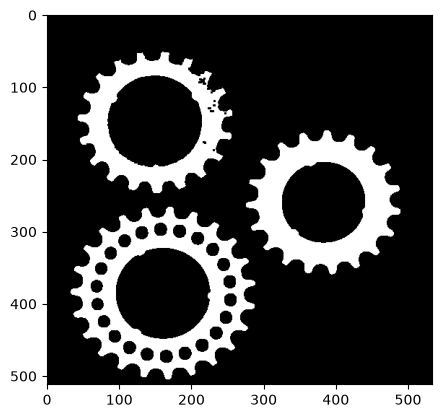

In [11]:
def erosion(img, k_size):
    """
    Inputs:
    img: Input Bild
    k_size: Kernelgröße

    Output:
    img_e: erodiertes Bild
    """
    
    pad = k_size//2
    img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=1) #Rand mit 1 auffüllen, sonst wird vom Bildrand her erodiert
    y, x = img.shape
    y_out = y - k_size + 1
    x_out  = x - k_size + 1

    img_e = np.zeros((y_out, x_out))
    for i in range(y_out):
        for j in range(x_out):
            img_e[i][j] = np.min(img[i:i+k_size, j:j+k_size])
    return img_e

img_e = erosion(img, 3)
plt.imshow(img_e,cmap='gray')

### Dilatation

Bei der Dilatation wird der Pixel durch den hellsten Pixel innerhalb der Kernelgröße ersetzt.
Die Artefakte im linken oberen Zahnrad schließen sich. Das Objekt vergrößert sich leicht.


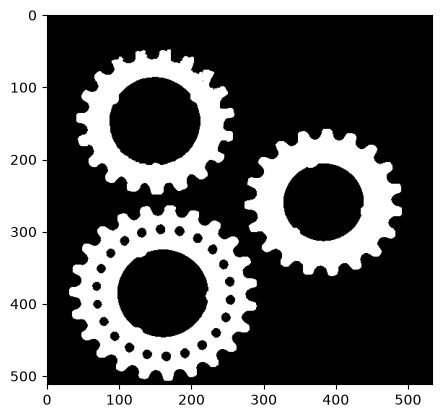

In [12]:
def dilation(img, k_size):
    """
    Inputs:
    img: Input Bild
    k_size: Kernelgröße

    Output:
    img_d: dilatiertes Bild
    """
    
    pad = k_size//2
    img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0) #Zero Padding
    y, x = img.shape
    y_out = y - k_size + 1
    x_out  = x - k_size + 1

    img_d = np.zeros((y_out, x_out))
    for i in range(y_out):
        for j in range(x_out):
            img_d[i][j] = np.max(img[i:i+k_size, j:j+k_size])
    return img_d

img_d = dilation(img, 3)
plt.imshow(img_d,cmap='gray')

Hier werden die Funktionen mit OpenCV implementiert. Verändern Sie die Kernelgröße und wenden Sie die Operationen mehrfach an, indem Sie das Argument `iterations` verändern.

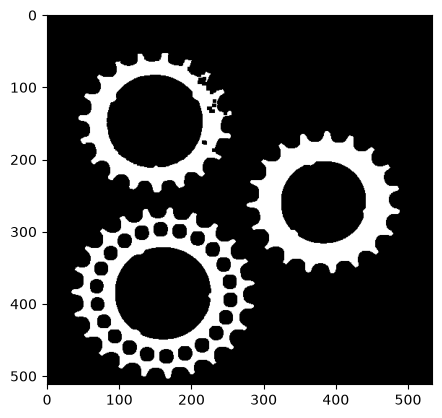

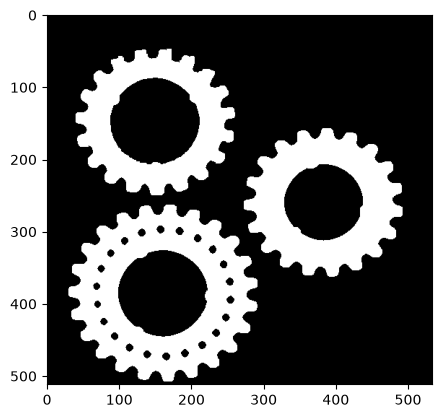

In [13]:
kernel = np.ones((3,3),np.uint8)
img_e = cv2.erode(img, kernel, iterations=2)
img_d = cv2.dilate(img, kernel, iterations=2)
plt.imshow(img_e,cmap='gray')
plt.show()
plt.imshow(img_d,cmap='gray')

### Opening und Closing
Verwenden Sie die OpenCV-Funktionen [`cv2.erode()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gaeb1e0c1033e3f6b891a25d0511362aeb) und [`cv2.dilate()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga4ff0f3318642c4f469d0e11f242f3b6c), um daraus die Opening und Closing Operation aufzubauen.

Opening: entfernt umgebende Artefakte (im Beispiel die Sterne)
1. Erosion
2. Dilatation

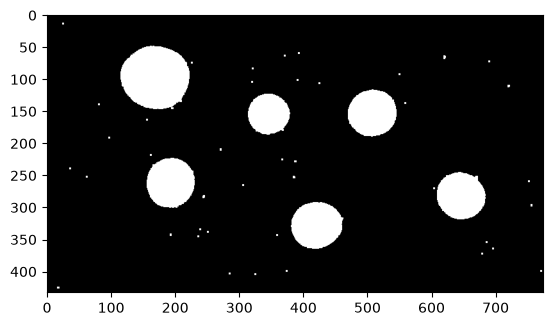

In [14]:
def opening(img, kernel, iterations):
    # Code hier
    img_o = cv2.erode(img, kernel, iterations=iterations)
    img_o = cv2.dilate(img_o, kernel, iterations=iterations)
    return img_o

img_o = opening(nightsky, kernel, 1)
plt.imshow(img_o,cmap='gray')

Closing: schließt Artefakte auf dem Objekt (im Beispiel Artefakte auf dem Zahnrad)
1. Dilatation
2. Erosion

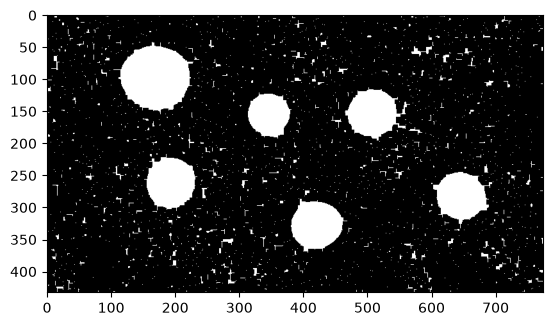

In [15]:
def closing(img, kernel, iterations):
    # Code hier
    img_c = cv2.dilate(img, kernel, iterations=iterations)
    img_c = cv2.erode(img_c, kernel, iterations=iterations)
    return img_c

img_c = closing(nightsky, kernel, 3)
plt.imshow(img_c,cmap='gray')

### Morphologischer Gradient

$\text{MG(Bild) = Dilatation(Bild) – Erosion(Bild)}$

Durch die Differenz zwischen Dilatation und Erosion zeigen sich die Kanten im Bild.

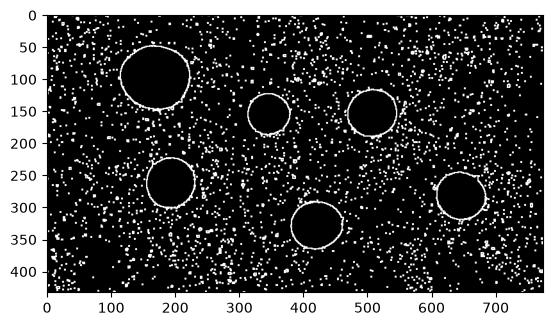

In [16]:
def gradient(img, kernel, iterations):
    # Code hier
    img_g = cv2.dilate(img, kernel, iterations=iterations) - cv2.erode(img, kernel, iterations=iterations)
    return img_g

img_g = gradient(nightsky, kernel, 1)
plt.imshow(img_g,cmap='gray')

### Tophat Transformationen

$\text{WTH(Bild) = Bild – Opening(Bild)}$

Bei der weißen Tophat-Transformation (WTH) zeigen sich die Artefakte um den Fingerabdruck.


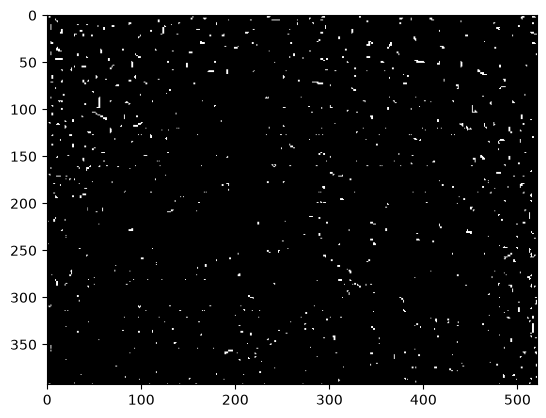

In [17]:
def tophat(img, kernel, iterations):
    # Code hier
    img_t = img - opening(img, kernel, iterations)
    return img_t

img_t = tophat(fingerprint, kernel, 1)
plt.imshow(img_t,cmap='gray')

$\text{BTH(Bild) = Closing(Bild) - Bild}$

Die schwarze Transformation (BTH) hebt die Artefake auf dem Fingerabdruck hervor.

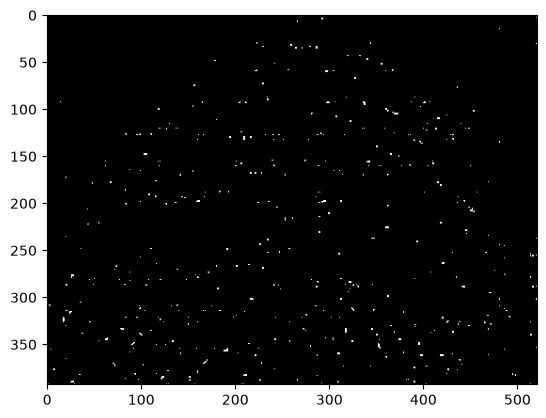

In [18]:
def blackhat(img, kernel, iterations):
    # Code hier
    img_b = closing(img, kernel, iterations) - img
    return img_b

img_b = blackhat(fingerprint, kernel, 1)
plt.imshow(img_b,cmap='gray')

Mit der Funktion [`cv2.morphologyEx()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga67493776e3ad1a3df63883829375201f) lassen sich die zusammengesetzten Operationen implementieren. Hierfür wird das entsprechende Argument an der zweiten Stelle eingefügt:
- Opening: `cv2.MORPH_OPEN` (Bei den Iterationen wird erst nur erodiert und dann nur dilatiert)
- Closing: `cv2.MORPH_CLOSE`
- Morphologischer Gradient: `cv2.MORPH_GRADIENT`
- White top-hat: `cv2.MORPH_TOPHAT`
- Black top-hat: `cv2.MORPH_BLACKHAT`

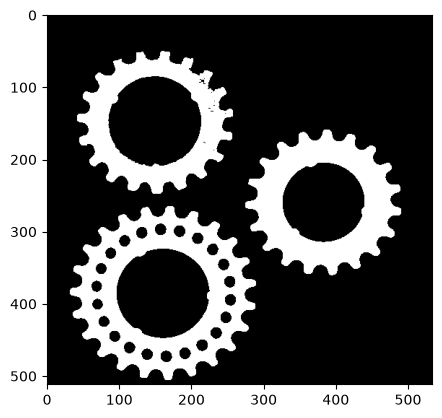

In [19]:
img = gears

img_m = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel, iterations=1)
plt.imshow(img_m,cmap='gray')

Wenden Sie die Operationen an, um:
- die Zellen voneinander zu trennen, damit sie gezählt werden können
- die weißen Artefakte beim Fingerabdruck zu entfernen
- die Kanten der Zahnräder sichtbar zu machen
- die weißen Kreise vom Sternenhimmel zu entfernen

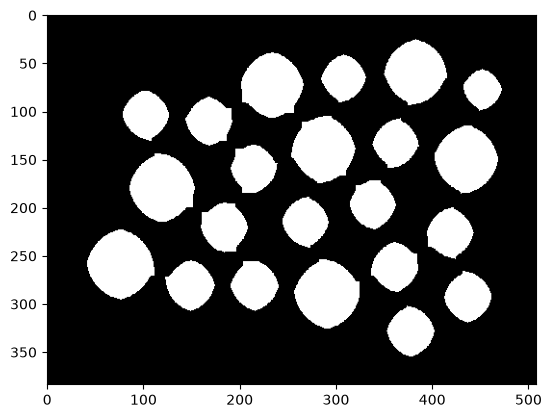

In [20]:
img = cells

# Code hier
img = erosion(img, 15)
plt.imshow(img,cmap='gray')

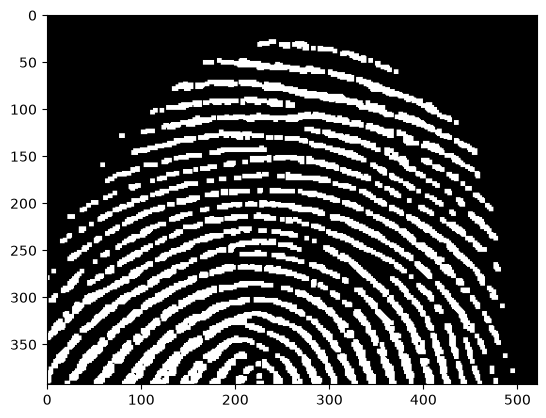

In [21]:
img = fingerprint

# Code hier
img = opening(img, kernel, 2)
plt.imshow(img,cmap='gray')

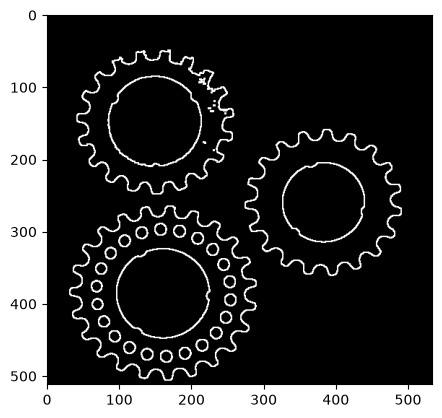

In [26]:
img = gears

# Code hier
img = dilation(img, 3) - erosion(img, 3)
plt.imshow(img, cmap='gray')


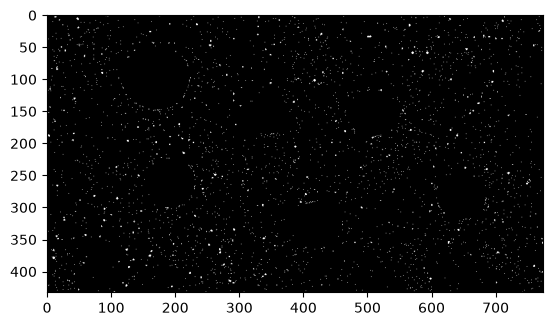

In [30]:
img = nightsky

# Code hier
img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel, iterations = 1)
plt.imshow(img, cmap='gray')

### Skelettierung

Das Bild wird schrittweise erodiert. Kurz bevor ein Teil des Objekts verschwindet, bleibt seine Mittellinie übrig – diese wird mit dem Top-Hat in `img_s` gespeichert. Alle gespeicherten Linien zusammen ergeben das Skelett.

Beim Anzeigen der Bilder lässt sich beobachten, wie `img` erodiert und die Mittellinien in `img_s` gesammelt werden.

Alternativ hat die [scikit-image](https://scikit-image.org/)-Bibliothek die Funktion [`skeletonize()`](https://scikit-image.org/docs/stable/auto_examples/edges/plot_skeleton.html) (Ausdünnen/Thinning).

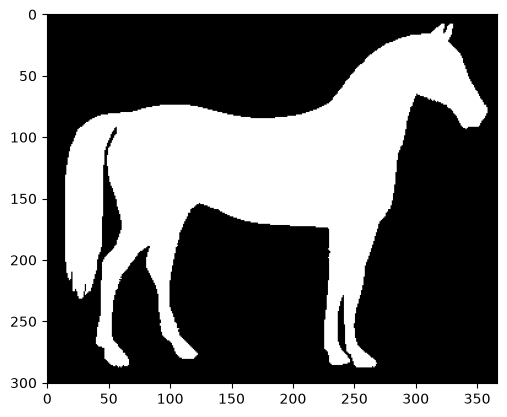

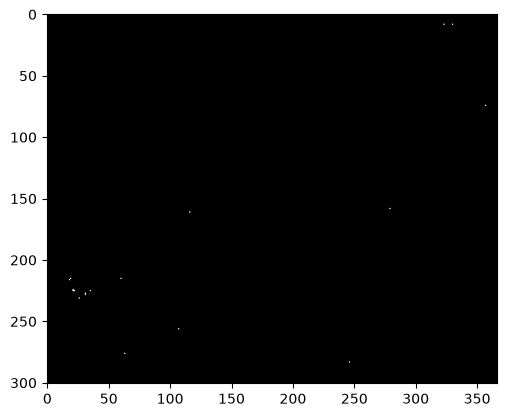

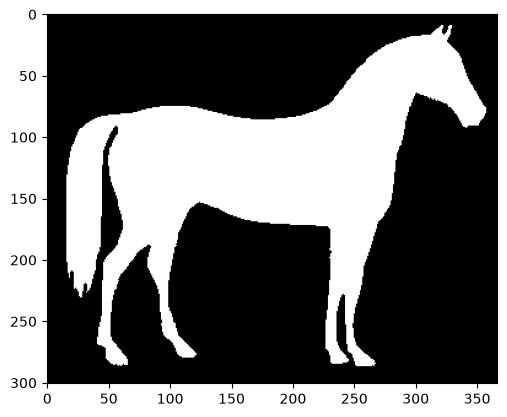

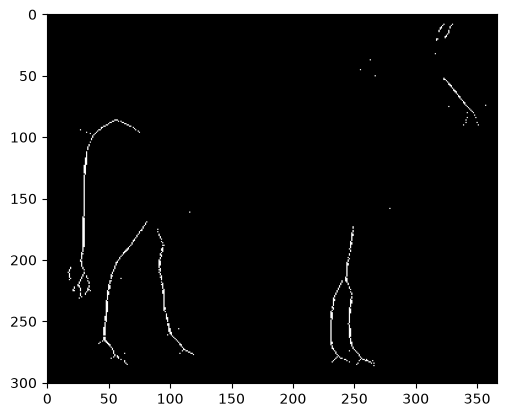

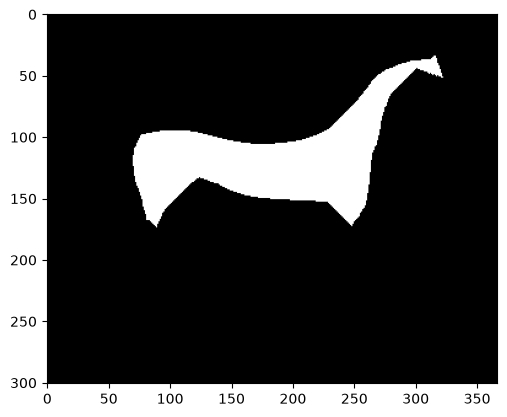

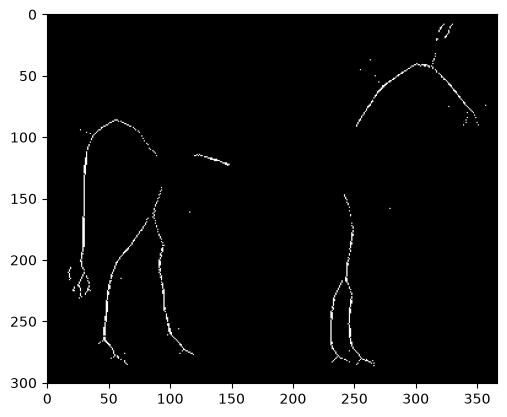

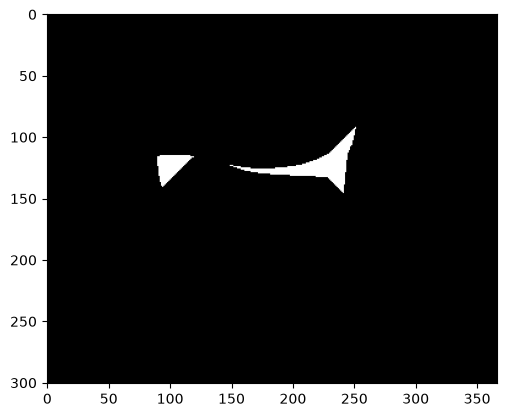

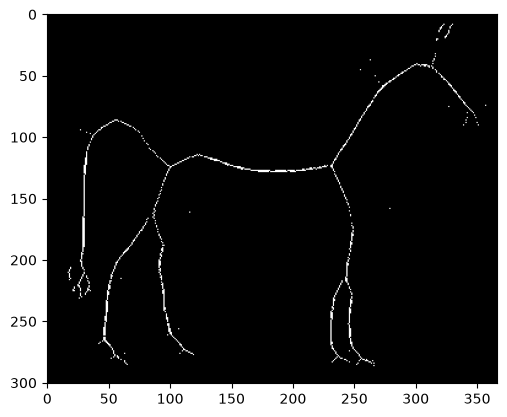

In [33]:
img = binary(cv2.imread('horse.png',0))
plt.imshow(img, cmap='gray')
plt.show()

size = np.size(img)
img_s = np.zeros(img.shape,np.uint8)
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS,(3,3)) #Kernel mit 4-Nachbarschaft

i = 0
while True:
    img_e = cv2.erode(img, kernel) #Erosion
    img_t = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel, iterations=1) #Tophat
    img_s = cv2.bitwise_or(img_s, img_t)
    img = img_e

    zeros = size - cv2.countNonZero(img)
    if zeros==size:
        break

    # Anzeigen jeder 20. Iteration
    if i%20 == 0:
        plt.imshow(img_s, cmap='gray')
        plt.show()
        plt.imshow(img, cmap='gray')
        plt.show()
    i += 1


plt.imshow(img_s, cmap='gray')